# SQG turbulence at $N = 128$, linear observations

Two-surface SQG on a doubly periodic $20\,000\,$km square, $128^2$ points per surface
($156\,$km spacing), $d = 2N^2 = 32768$, Rossby radius $L_R = 1000\,$km, surfaces at $z = 0$
and $z = H = 10\,$km. $N_e = 16$ members, so the state dimension exceeds the ensemble size by
more than three orders of magnitude.

| | |
|---|---|
| analyses | 6-hourly, 100 cycles, cycles 50-99 scored |
| observations | $\theta$ at $10\,\%$ of the $2N^2$ points, both surfaces, network redrawn each cycle |
| operator | identity, $\sigma_{\rm obs} = 1\,$K |
| initial ensemble | climatological, 16 states from a long free run |
| seeds | 10 evaluation (0-9), 3 tuning (100-102), disjoint |

Both methods have their localization tuned and the LETKF its inflation, on the tuning seeds.
CI-EnSF uses the simplified prior-scaling rule,
$\gamma \leftarrow \mathrm{clip}(\gamma\,\rho_s^{1/2}, 0.05, 0.5)$, with $\kappa = 0.025$.
The LETKF does not use that controller; it is re-run alongside CI-EnSF so that both methods
are scored on the same trajectories.

**Produces** Table 4 and Figure 5 of the manuscript. The selected hyperparameters are
hard-coded in section 1. `RUN_SIMULATION = False` rebuilds them from the stored results in
`sqg/`; `True` re-runs the filters, which needs a GPU and the nature runs (not distributed
with the code).

## 1. Configuration and the selected settings

In [1]:
import os, sys, json, numpy as np
import matplotlib
import matplotlib.pyplot as plt

def _find_sqg():
    """Walk up from the working directory until a sqg/ directory appears.  This notebook
    sits one level deeper than the repository's other SQG notebooks, and the same file is
    used both in the development tree and in the reproducibility repository, so the path is
    resolved rather than written down."""
    p = os.path.abspath(os.curdir)
    for _ in range(4):
        cand = os.path.join(p, "sqg")
        if os.path.isdir(cand):
            return cand
        p = os.path.dirname(p)
    raise SystemExit("could not locate the sqg/ directory; set CIENSF_SQG to point at it")

SQG = os.environ.get("CIENSF_SQG") or _find_sqg()
sys.path.insert(0, SQG)

RUN_SIMULATION = False      # True -> re-run the filters (GPU, and needs sqg/nature/)

# ---------------- the experiment, exactly as the filters were run
N, D, KENS   = 128, 2*128*128, 16
L_DOM, LR, H = 20000e3, 1000e3, 10e3
DT_OBS_H     = 6.0
N_CYCLE, SCORE_FROM = 100, 50
EVAL_SEEDS   = tuple(range(10))

# ---------------- selected hyperparameters, all literals.  The sweeps that produced them
# (localization radius per method, the annealing strength, the LETKF's inflation) are not
# re-run here; they are archived in xlayer_exp.py and the results files beside it.
LLOC_KM      = 1000         # both methods; tuned separately on seeds 100-102
KAPPA        = 0.025        # CI-EnSF likelihood annealing
RTPS         = 0.5          # LETKF relaxation to prior spread
OBS_FRAC     = 0.10         # 10 % of the 2 N^2 grid points, both levels, redrawn each cycle
SIGMA_OBS    = 1.0          # K
# gamma controller (simplified rule):  gamma <- clip(gamma * rho_s**P_GAIN, LO, HI)
GAMMA0, GAMMA_LO, GAMMA_HI = 0.1, 0.05, 0.5
P_GAIN, W_SMOOTH           = 0.5, 0.3

EVAL_JSON = os.path.join(SQG, "sqg_n128_linear_simple.json")
FLD_NPZ   = os.path.join(SQG, "figure_fields.npz")

# The snapshot figure draws one level at the final cycle, so only that is kept, with the
# colour limits it uses.  Those are taken over every cycle, as the full run would give them.
FIG_LEV = 1
def figure_fields(f):
    T = f["truth"][:, FIG_LEV]
    E = [f[m][:, FIG_LEV] - T for m in ("CI-EnSF", "LETKF")]
    out = {m: f[m][-1, FIG_LEV] for m in ("truth", "CI-EnSF", "LETKF")}
    out.update({m + s: f[m + s] for m in ("CI-EnSF", "LETKF")
                for s in ("_rmse_obs", "_rmse_unobs")})
    out["vmax"] = np.abs(T).max()
    out["dmax"] = np.percentile(np.abs(np.concatenate(E)), 99.5)
    return out

## 2. Re-running the filters

`RUN_SIMULATION = False` skips this section and the table and figure below are rebuilt from
the stored results. Setting it to `True` re-runs both filters over the ten evaluation seeds
and rewrites those files. That needs a GPU and the nature runs (see **Nature runs** in the
README); it takes roughly twenty minutes per seed for CI-EnSF and seconds for the LETKF.

Only CI-EnSF depends on the $\gamma$ controller, so the LETKF is re-run as well purely as a
check that the stored evaluation still reproduces.

In [2]:
if RUN_SIMULATION:
    import time
    os.environ.update(SQG_N="128", SQG_GPU="1", SQG_OBS="linear",
                      SQG_NCYC="200", SQG_CLIM="64", SQG_GAMMA_RULE="simple")
    import sqg_cvt as S, bfree, nature_cache as NC

    assert S.GAMMA_RULE == "simple", S.GAMMA_RULE
    S.LLOC = LLOC_KM*1e3
    S.BF   = bfree.BFree(S.N, S.L_DOM, S.LLOC, alpha=1.0)
    S.OBS_LEVEL, S.OBS_FRAC, S.INIT = "both", OBS_FRAC, "clim"
    S.GAMMA0, S.GAMMA_LO, S.GAMMA_HI = GAMMA0, GAMMA_LO, GAMMA_HI

    CFG = [("CI-EnSF", "adapt", dict(kappa=KAPPA)),
           ("LETKF",   "letkf", dict(kappa=0.0))]
    out, fields = {}, {}
    for name, mode, kw in CFG:
        if name == "LETKF": S.RTPS = RTPS
        per = []
        for seed in EVAL_SEEDS:
            T, C = NC.load(seed); S.nature_run = lambda _s, _T=T, _C=C: (_T, _C)
            if seed == 0:
                S.run.field_sink = []                 # Figure 5 draws seed 0
                fields["truth"] = np.asarray(T[:N_CYCLE], np.float32)
            t0 = time.time()
            h, f = S.run(seed, mode, nc=N_CYCLE, verbose=False, **kw)
            h = np.asarray(h); w = h[SCORE_FROM:]
            per.append(dict(seed=seed, status="ok" if f is None else "fail",
                            rmse=float(w[:, 0].mean()), sprms=float(w[:, 2].mean()),
                            rmse_obs=float(w[:, 10].mean()),
                            rmse_unobs=float(w[:, 11].mean()),
                            gamma=float(w[:, 3].mean()), secs=time.time() - t0))
            if seed == 0:
                fields[name] = np.asarray(S.run.field_sink, np.float32)
                del S.run.field_sink
                for suf, col in (("_rmse", 0), ("_rmse0", 6), ("_rmse1", 7),
                                 ("_rmse_obs", 10), ("_rmse_unobs", 11)):
                    fields[name + suf] = h[:, col].astype(np.float32)
            print("  %-9s seed %d  rmse %.4f  [%.0f s]"
                  % (name, seed, per[-1]["rmse"], per[-1]["secs"]), flush=True)
        ok = [q for q in per if q["status"] == "ok"]
        r  = np.array([q["rmse"] for q in ok])
        out[name] = dict(per_seed=per, n=len(per), n_ok=len(ok),
                         rmse_all=float(r.mean()), worst=float(r.max()),
                         sprms=float(np.mean([q["sprms"] for q in ok])),
                         rmse_obs=float(np.mean([q["rmse_obs"] for q in ok])),
                         rmse_unobs=float(np.mean([q["rmse_unobs"] for q in ok])),
                         gamma=float(np.mean([q["gamma"] for q in ok])))

    json.dump(dict(n_cycle=N_CYCLE, score_from=SCORE_FROM, lloc_km=LLOC_KM, kappa=KAPPA,
                   rule="simple", gamma0=GAMMA0, gamma_lo=GAMMA_LO, gamma_hi=GAMMA_HI,
                   seeds=list(EVAL_SEEDS), batched=bool(S.BATCH), results=out),
              open(EVAL_JSON, "w"), indent=1)
    np.savez_compressed(FLD_NPZ, **figure_fields(fields))

EV  = json.load(open(EVAL_JSON))
FLD = np.load(FLD_NPZ)


## 3. Table 4

Five columns: method, stable realizations, mean analysis RMSE over cycles 50-99 and over the
ten seeds, the largest realization-mean RMSE among them, and spread/RMSE. The
finite-ensemble reference for spread/RMSE is $\sqrt{N_e/(N_e+1)} = 0.970$ at $N_e = 16$.

In [3]:
# Row order follows the manuscript: the method under test first, then the baseline.
ORDER = ["CI-EnSF", "LETKF"]

def latex_table():
    o = [r"\begin{tabular}{lcccc}", r"\toprule",
         r"Method & Stable realizations & RMSE (K) & Worst RMSE (K) & Spread/RMSE \\",
         r"\midrule"]
    for m in ORDER:
        r = EV["results"][m]
        o.append("%s & %d/%d & %.4f & %.4f & %.2f \\\\"
                 % (m, r["n_ok"], r["n"], r["rmse_all"], r["worst"], r["sprms"]))
    o += [r"\bottomrule", r"\end{tabular}"]
    return "\n".join(o)

print(latex_table())


\begin{tabular}{lcccc}
\toprule
Method & Stable realizations & RMSE (K) & Worst RMSE (K) & Spread/RMSE \\
\midrule
CI-EnSF & 10/10 & 1.4671 & 1.6028 & 0.98 \\
LETKF & 10/10 & 1.2553 & 1.3452 & 1.03 \\
\bottomrule
\end{tabular}


## 4. Figure 5

The final analysis cycle of seed 0. (a)-(c) the truth and the two analyses at the upper
surface; (e)-(f) the corresponding error fields on a common colour scale; (d) analysis RMSE
per cycle, split into the directly observed and the unobserved components.

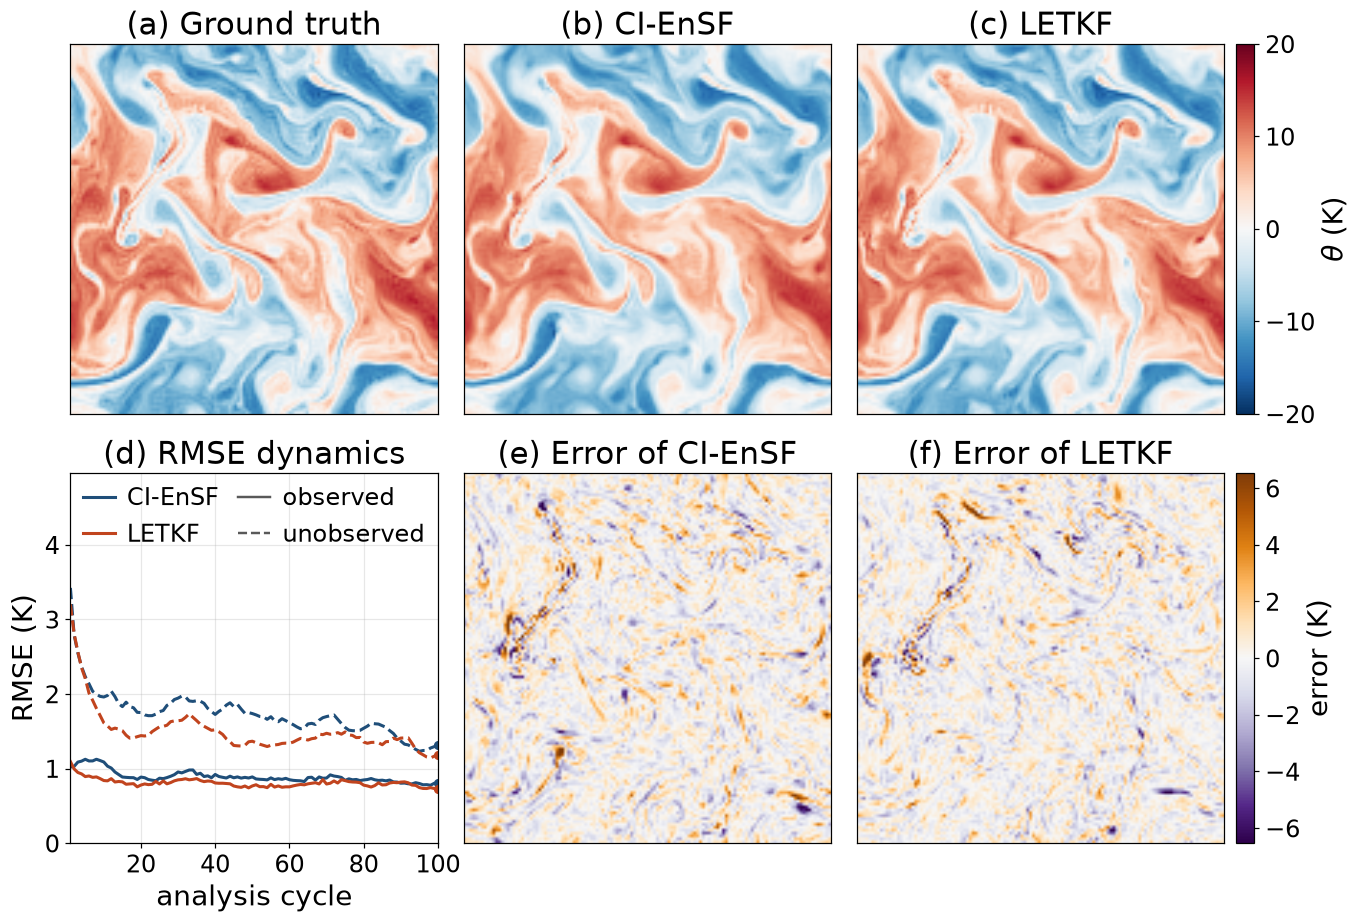

In [4]:
from matplotlib.lines import Line2D

# level FIG_LEV at the final cycle; the colour limits come with it (see figure_fields)
truth, cvtF, letF = FLD["truth"], FLD["CI-EnSF"], FLD["LETKF"]
dC, dL = cvtF - truth, letF - truth
SER   = (FLD["CI-EnSF_rmse_obs"], FLD["CI-EnSF_rmse_unobs"],
         FLD["LETKF_rmse_obs"],    FLD["LETKF_rmse_unobs"])
NF    = len(SER[0])
VMAX, DMAX = float(FLD["vmax"]), float(FLD["dmax"])
EXT   = [0, L_DOM/1e3, 0, L_DOM/1e3]

# one place to set the type sizes, so the figure can be made legible at print size.
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG = 20, 18, 16, 16

def build():
    """The six panels at the final analysis cycle."""
    plt.rcParams.update({"font.size": FS_LABEL, "figure.dpi": 110})
    fig = plt.figure(figsize=(13.0, 8.6))
    # A plain 2x3 grid: every panel, maps and line plot alike, gets the same box.  The
    # colourbars are placed by hand below so the gap to the maps is set, not inherited
    # from a spacer column.
    gs  = fig.add_gridspec(2, 3, hspace=0.16, wspace=0.07)
    A   = [fig.add_subplot(gs[0, i]) for i in range(3)]
    B1  = fig.add_subplot(gs[1, 0])
    B   = [fig.add_subplot(gs[1, i]) for i in (1, 2)]
    ims = []
    for a, f, t in zip(A, (truth, cvtF, letF),
                       ("(a) Ground truth", "(b) CI-EnSF", "(c) LETKF")):
        ims.append(a.imshow(f, origin="lower", extent=EXT, cmap="RdBu_r", aspect="auto",
                            vmin=-VMAX, vmax=VMAX, interpolation="bilinear"))
        a.set_title(t, fontsize=FS_TITLE)
        a.set_xticks([]); a.set_yticks([])   # bare maps: the frame is the only decoration
    for b, d, t in zip(B, (dC, dL), ("(e) Error of CI-EnSF", "(f) Error of LETKF")):
        ims.append(b.imshow(d, origin="lower", extent=EXT, cmap="PuOr_r", aspect="auto",
                            vmin=-DMAX, vmax=DMAX, interpolation="bilinear"))
        b.set_title(t, fontsize=FS_TITLE)
        b.set_xticks([]); b.set_yticks([])

    k = np.arange(1, NF+1)
    style = (("#1f4e79","-"), ("#1f4e79","--"), ("#c1441e","-"), ("#c1441e","--"))
    for y, (c, ls) in zip(SER, style):
        B1.plot(k, y, color=c, ls=ls, lw=2.0); B1.plot([NF], [y[-1]], "o", color=c, ms=5)
    B1.set_xlim(1, NF)
    B1.set_ylim(0.0, 1.45*max(SER[1].max(), SER[3].max()))   # linear, from zero
    B1.set_xlabel("analysis cycle", fontsize=FS_LABEL)
    B1.set_ylabel("RMSE (K)", fontsize=FS_LABEL)
    B1.set_title("(d) RMSE dynamics", fontsize=FS_TITLE)
    B1.grid(alpha=.3); B1.tick_params(labelsize=FS_TICK)
    B1.legend(handles=[Line2D([],[],color="#1f4e79",lw=2.0,label="CI-EnSF"),
                       Line2D([],[],color="#c1441e",lw=2.0,label="LETKF"),
                       Line2D([],[],color="0.35",lw=1.6,ls="-", label="observed"),
                       Line2D([],[],color="0.35",lw=1.6,ls="--",label="unobserved")],
              fontsize=FS_LEG, loc="upper right", frameon=False, ncol=2,
              handlelength=1.3, handletextpad=0.5, columnspacing=0.8,
              borderaxespad=0.15)   # at FS_LEG=16 the legend is 3.30 in and the panel 3.34,
                                    # so it only clears the left spine with the padding cut
    fig.subplots_adjust(left=0.065, right=0.872, top=0.945, bottom=0.100)

    GAP, CW = 0.008, 0.013          # map-to-colourbar gap and bar width, figure fractions
    for src, row, lab in ((ims[0], A[2], r"$\theta$ (K)"), (ims[3], B[1], "error (K)")):
        p  = row.get_position()
        cb = fig.colorbar(src, cax=fig.add_axes([p.x1 + GAP, p.y0, CW, p.height]))
        cb.set_label(lab, fontsize=FS_LABEL); cb.ax.tick_params(labelsize=FS_TICK)

    return fig

fig = build()
# written next to the notebook, as every other figure in this repository is
fig.savefig("sqg_n128_snapshot.pdf")
fig.savefig("sqg_n128_snapshot.png", dpi=140)
plt.show()